# Formation Review for dance judges

Formation Review helps dance judges assess group formation accuracy. Judges can pause the video, see fitted lines on the 12 × 12 m stage map, and review how closely the dancers align in each detected row.

Floor contacts give us the stage positions used to fit those lines. The live heat map adds a view of how widely the group uses the stage and where dancers spend the most time.

We developed the tool on the original fixed-camera choreography and visually checked it on Wicked Games, onare and Dernek. The team roadmap records verbal approval to use dance for the challenge.

[Interactive replay](dashboard/index.html) · [Research evidence](Research_Notebook.ipynb) · [Labeling guide](Labeling_Guide.ipynb) · [Rubric and remaining work](docs/rubric_and_gaps.md)

The cells below read saved experiment evidence and run on CPU. [Run a fresh clip](README.md) to execute the detector, tracker, support model, map and export from an MP4.

In [1]:
from pathlib import Path
from csv import DictReader
import json
from IPython.display import Image, Markdown, Video, display

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'tools/run_notebooks.py').is_file())
exp = root / 'Experiment'
early = exp / 'Dance_Overnight'
trial = exp / 'lighting_expansion_300'
evidence = root / 'experiments'
run = trial / 'runs/lighting_300_visual_s17'

def load(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))

def table(headers, rows):
    lines = ['| ' + ' | '.join(headers) + ' |', '|' + '|'.join(['---'] * len(headers)) + '|']
    lines += ['| ' + ' | '.join(map(str, row)) + ' |' for row in rows]
    display(Markdown('\n'.join(lines)))

def show(path, width=930):
    display(Image(filename=str(path), width=width))

## 1. Locate the dancers on the stage

Generic YOLO finds many standing dancers. Overlapping crops help keep small performers large enough for inference, then cross-crop IoU suppression merges duplicates. Tracking links detections across frames. We first used the bottom of each box as the dancer's floor position. During floor work, a knee, seat or palm may be the clearest point to project onto the stage. The learned head uses a body crop to estimate that point and whether the frame provides enough evidence to report it.

[Tiled detector](Experiment/Dance_Overnight/code/detector_probe.py) · [Contact model and crop averaging](Experiment/Dance_Overnight/code/candidate_evaluate.py)

| Development comparison | Within 3% of width | Hidden reported |
|---|---|---|
| Box geometry | 88/104 | 29 |
| Learned contact | 99/104 | 4 |

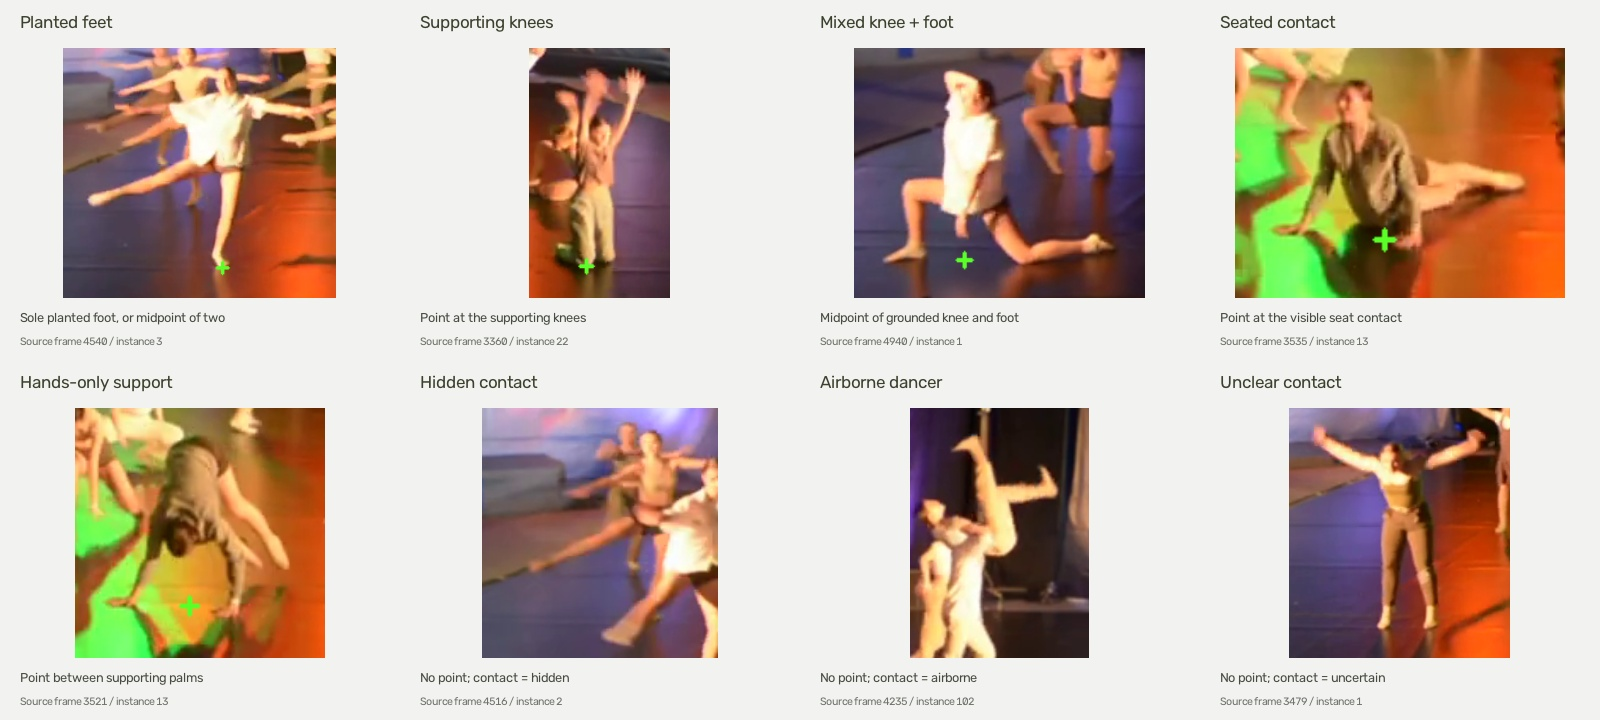

In [2]:
geometry = load(early / 'geometry/results.json')['chosen']['validation']['selected']
learned = load(early / 'ending_experiment/results.json')['reference']['old_development']['selected']
table(['Development comparison', 'Within 3% of width', 'Hidden reported'],
      [[name, f"{row['correct']}/{row['refs']}", row['hidden_emitted']]
       for name, row in [('Box geometry', geometry), ('Learned contact', learned)]])
show(early / 'figures/label_examples.jpg')

## 2. Label the difficult examples

The pilot used 60 training frames and 11 validation frames. The 200-frame revision added lighting and floor-work variation, then the final run added another 100. We corrected proposals for cut-off boxes, duplicates, missed dancers and misplaced contacts. Only a visible contact gets a point. Hidden, airborne and uncertain remain separate label states.

A/B/C are review batches. The saved work documents model-assisted proposals and assistant visual review. The blind repeat was by the assistant and is evidence of repeatability within that workflow. Independent agreement still requires separate team labels.

In [3]:
audit = load(trial / 'structural_qa.json')
split = load(evidence / 'data/split_audit.json')
table(['Pack', 'Frames', 'Boxes', 'Visible contact points'],
      [[name, row['frames'], row['dancer_boxes'], row['support_points']] for name, row in audit['parts'].items()])
print(f"{split['unique_verified_training_files']} verified unique training files; "
      f"{split['minimum_train_validation_gap_frames']} frames at the closest train/validation boundary.")
print(f"Reserved exclusion: {split['reserved_excluded_inclusive']}. Same performance across splits.")

| Pack | Frames | Boxes | Visible contact points |
|---|---|---|---|
| A | 100 | 1830 | 1331 |
| B | 100 | 1821 | 1360 |
| C | 100 | 1808 | 1377 |

300 verified unique training files; 11 frames at the closest train/validation boundary.
Reserved exclusion: [3938, 4092]. Same performance across splits.


## 3. Fine-tune and compare the box detectors

The 300-frame detector starts from the earlier dance checkpoint and fine-tunes on tiled dancer boxes. It freezes the first ten layers, uses AdamW with learning rate 0.00025, and keeps mosaic off. For the comparison below we reran all three checkpoints with the same tiles, 960-pixel inference and merge IoU. AP integrates the precision–recall curve at an IoU threshold. AP50:95 averages ten IoU thresholds, so it penalizes loose boxes more.

The 300-frame model leads development AP50. Generic YOLO leads AP50:95 on both available diagnostic splits. We kept the joint model for the interactive demo because its contact benchmark shows better tight localization and fewer hidden reports. The two tests measure different things.

In [4]:
report = load(evidence / 'detector/comparison.json')
names = {'generic': 'COCO YOLO26m', 'published': 'Earlier dance detector', 'tuned_300': '300-image detector'}
def ap_row(key):
    dev = report['models'][key]['development']
    reserved = report['models'][key]['reserved_diagnostic']
    return [names[key], f"{dev['mAP50']:.3f}", f"{dev['mAP50_95']:.3f}",
            f"{reserved['mAP50']:.3f}", f"{reserved['mAP50_95']:.3f}"]
table(['Detector', 'Dev AP50', 'Dev AP50:95', 'Reserved AP50', 'Reserved AP50:95'],
      [ap_row(key) for key in names])

| Detector | Dev AP50 | Dev AP50:95 | Reserved AP50 | Reserved AP50:95 |
|---|---|---|---|---|
| COCO YOLO26m | 0.844 | 0.538 | 0.723 | 0.593 |
| Earlier dance detector | 0.799 | 0.465 | 0.753 | 0.413 |
| 300-image detector | 0.869 | 0.466 | 0.705 | 0.433 |

## 4. Diagnose errors before changing the model

On frame 4021 a dancer supporting their weight on a hand and foot is spread across the floor. The tuned detector's visible body box is too short for one reference, and overlapping predictions can also go unmatched. Frame 4061 shows how several nearby bodies make the same problem worse. Amber is unmatched against these references. Some cases need human review before calling them background false positives.

This drove the visible-extent labeling rule. More labels improved development recall for hidden-contact dancers but did not carry over to the reserved diagnostic. The next controlled change is to correct a separate set of crowded frames, then test overlap handling at fixed settings.

Earlier dance detector matched / reference boxes: 83 / 103
300-image detector matched / reference boxes: 79 / 103


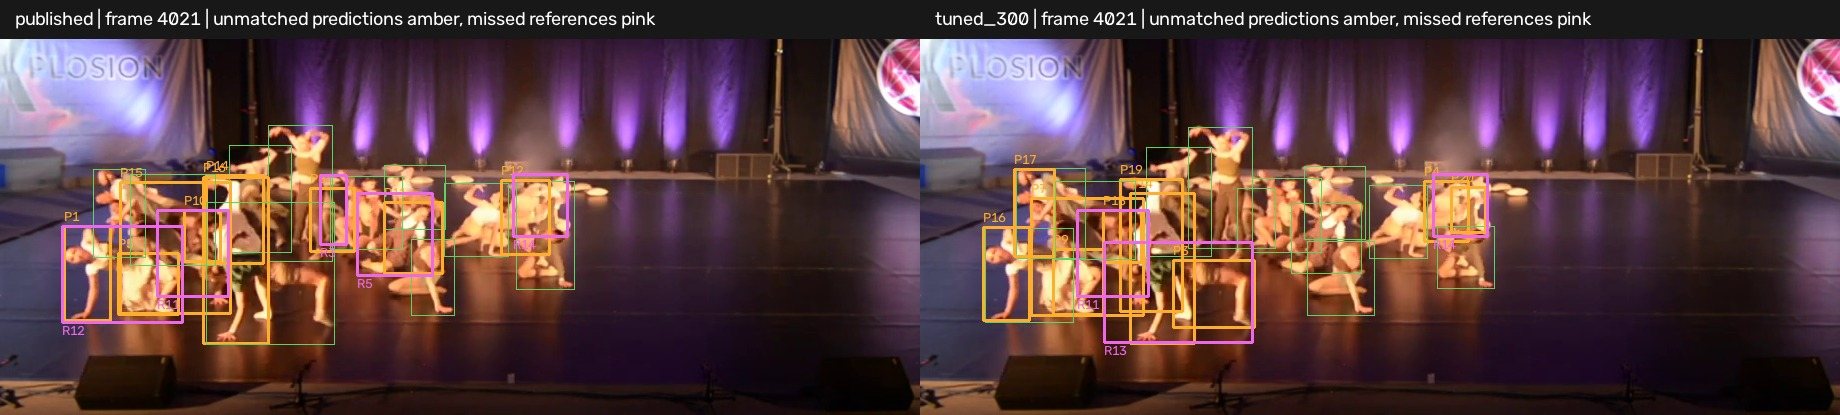

In [5]:
for key in ('published', 'tuned_300'):
    comparison = report['models'][key]['reserved_diagnostic']
    print(names[key], 'matched / reference boxes:', comparison['matched_at_025_iou50'], '/', comparison['reference_boxes'])
show(evidence / 'error_analysis/frame_4021.jpg')

## 5. Project contacts onto a square stage

Four ordered coplanar correspondences give enough constraints for a perspective map. We project the support point through a 3×3 homography and divide by the last coordinate. The stage is 12 × 12 m, so both map axes use the same scale. The original calibration extrapolates the front corners. A jump breaks the floor-plane assumption, so the label has no measured point. The three new recordings register fixed venue landmarks to adjust the map during zooms and shifts.

[Original calibration](Experiment/Dance_CVAT_Pilot/calibration_draft.json) · [Camera registration](tools/register_external_stage.py)

In [6]:
cal = load(exp / 'Dance_CVAT_Pilot/calibration_draft.json')
H = cal['pixel_to_relative_mat_homography']
def project_pixel(point):
    x, y, w = [sum(a*b for a, b in zip(row, [*point, 1])) for row in H]
    return round(12*x/w, 2), round(12*y/w, 2)
check = load(evidence / 'geometry/edge_check.json')
print('Corners on the map in meters:', [project_pixel(p) for p in cal['image_points']])
print(f"Median edge residual: {check['baseline_median_pixel_edge_error']:.2f} → "
      f"{check['draft_median_pixel_edge_error']:.2f} px on {check['independent_edge_picks_same_image']} separate edge picks.")

Corners on the map in meters: [(0.0, 0.0), (12.0, -0.0), (12.0, 12.0), (0.0, 12.0)]
Median edge residual: 12.34 → 0.36 px on 14 separate edge picks.


## 6. Compare contacts and choose the replay threshold

The seven reserved images contain 46 visible and 50 hidden reference contacts. Missing visible predictions count as misses. The 300-image joint model improves the tight 1% result and makes fewer hidden reports. The published pipeline still leads at 3%. These references were checked on one performance and reused in prior comparisons.

The offline trajectory fit uses future frames to stabilize motion and bridge some gaps. A hollow dot means an estimated position. For the demo we lowered reportability to 0.30 after comparing the number of displayed dots and replay jitter. The table uses thresholds selected on validation.

In [7]:
joint = load(run / 'joint_evaluation/results.json')
support = load(run / 'evaluation/results.json')
models = [
    ('Published baseline', joint['published_baseline']['all']),
    ('200-image support revision', joint['revision_200']['all']),
    ('300 support with earlier detector', support['candidate_300_support']['all']),
    ('300 support and detector', joint['candidate_300_joint']['all']),
]
table(['Pipeline', 'Within 1%', 'Within 2%', 'Within 3%', 'Within 5%', 'Hidden reported'],
      [[name, *[f"{value['correct_by_tolerance_pct_width'][k]}/46" for k in ('1','2','3','5')],
        f"{value['hidden_measured']}/50"] for name, value in models])

| Pipeline | Within 1% | Within 2% | Within 3% | Within 5% | Hidden reported |
|---|---|---|---|---|---|
| Published baseline | 11/46 | 21/46 | 29/46 | 30/46 | 5/50 |
| 200-image support revision | 9/46 | 21/46 | 26/46 | 30/46 | 3/50 |
| 300 support with earlier detector | 13/46 | 21/46 | 28/46 | 31/46 | 3/50 |
| 300 support and detector | 14/46 | 22/46 | 27/46 | 33/46 | 2/50 |

## 7. Measure formation alignment

We started with horizontal rows and then allowed tilted lines. The detector searches for narrow groups of dancer positions, fits a line to each group and checks that it persists across nearby frames. The dashboard defaults to four dancers and ±10°. A row scores 100% when every reported position lies on the fitted line. The score falls as the mean perpendicular distance grows and reaches zero at 6% of stage width. The overall score averages the detected rows.

Judges can use these scores to assess how cleanly dancers form rows, taking the intended choreography into account. The additional heat map shows cumulative stage use up to the playhead, with warmer areas showing more time spent there.

| New choreography | Frames processed | Frames with ≥1 contact | Frames with ≥1 line (4 dots, ±10°) |
|---|---|---|---|
| Wicked Games | 4,473 | 4,219 | 14 |
| onare | 4,713 | 4,684 | 641 |
| Dernek | 6,278 | 5,906 | 3,419 |

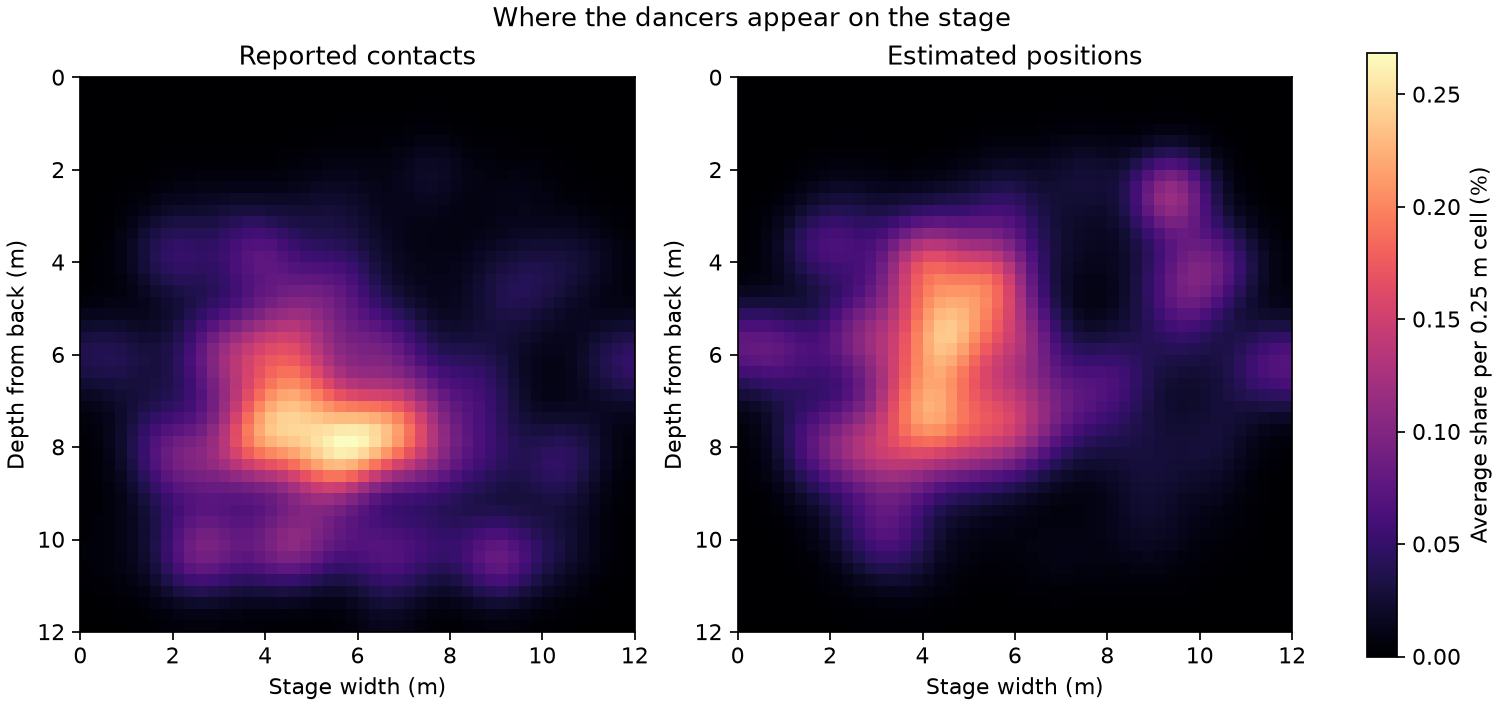

In [8]:
summary = load(evidence / 'replays/summary.json')
table(['New choreography', 'Frames processed', 'Frames with ≥1 contact', 'Frames with ≥1 line (4 dots, ±10°)'],
      [[r['title'], f"{r['frames']:,}", f"{r['frames_with_contacts']:,}", f"{r['frames_with_default_line']:,}"] for r in summary])
show(evidence / 'analytics/stage_occupancy.png')

## 8. Run it live in the defense

Open the dashboard and pause onare near 3:05 to inspect the fitted row and its alignment score. Change the angle or minimum dancer count and see how the fit changes. Then scroll to the live heat map and scrub through Dernek to see stage coverage build. Use the bundled 12-second clip in the upload app to demonstrate how an MP4 becomes a synchronized replay and position export. [Dashboard](dashboard/index.html) · [Upload app](README.md)

The highest priorities before submission are independent review of 30–45 frames and an annotated holdout from a different performance. [Rubric checklist](docs/rubric_and_gaps.md) · [Casebook](docs/error_casebook.md) · [Decision log](docs/experiment_log.md) · [AI disclosure](docs/genai_disclosure.md) · [Defense notes](docs/defense_notes.md)

In [9]:
for label, folder in [('RTX sample', 'rtx_sample'), ('CPU smoke test', 'cpu_smoke')]:
    meta = load(evidence / 'integration' / folder / 'metadata.json')
    print(f"{label}: {meta['frames']} frames, {meta['fps']:.0f} fps export; {meta['inference_fps']:.2f} fps inference")
display(Video(url='experiments/integration/rtx_sample/annotated_replay.mp4', width=930))

RTX sample: 300 frames, 25 fps export; 5.72 fps inference
CPU smoke test: 16 frames, 25 fps export; 0.80 fps inference
